# Análise Exploratória dos Dados (EDA)

## Projeto Integrador — Grupo 5
### Cidade Inteligente: Auditoria e Prevenção de Fraudes

**Responsável:** João Batista — FinOps / Machine Learning

## Objetivo

Explorar o dataset sintético PaySim, compreender o comportamento das transações legítimas e fraudulentas, avaliar a qualidade dos dados e investigar possíveis fontes de Data Leakage antes da definição das variáveis para modelagem.

## Organização do notebook

A análise está organizada em carregamento e compreensão da base, análise descritiva, qualidade dos dados, investigação de variáveis e conclusão de Data Leakage. A preparação e os experimentos de Machine Learning ficam no notebook `02_preparacao_e_modelagem.ipynb`.

### Dependências

O ambiente `.venv` do projeto utiliza pandas, NumPy, Matplotlib e scikit-learn. Em um ambiente novo, instale o scikit-learn com:

```powershell
python -m pip install scikit-learn
```

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Ambiente configurado com sucesso!")

Ambiente configurado com sucesso!


In [ ]:
caminho_arquivo = "../data/raw/PS_20174392719_1491204439457_log.csv"
df = pd.read_csv(caminho_arquivo)
print("Dataset carregado com sucesso!")

Dataset carregado com sucesso!


### ETAPA 1 — VERIFICAÇÃO DAS DIMENSÕES DO DATASET

In [ ]:
# ==========================================================
# 1. VERIFICAÇÃO DAS DIMENSÕES DO DATASET
# ==========================================================

# O atributo shape permite identificar as dimensões
# do DataFrame, retornando uma tupla com dois valores:
#
# Primeiro valor: quantidade de linhas (registros).
# Segundo valor: quantidade de colunas (variáveis).

dimensoes = df.shape

# Armazena separadamente a quantidade de registros
# e a quantidade de variáveis existentes no dataset.

total_registros = dimensoes[0]
total_colunas = dimensoes[1]

# Exibe as dimensões do conjunto de dados.

print(f"Total de registros: {total_registros:,}")
print(f"Total de variáveis: {total_colunas}")

Total de registros: 6,362,620
Total de variáveis: 12


### ETAPA 2 — IDENTIFICAÇÃO DAS COLUNAS DO DATASET

In [ ]:
# ==========================================================
# 2. IDENTIFICAÇÃO DAS COLUNAS DO DATASET
# ==========================================================

# O atributo columns acessa os nomes de todas as colunas
# existentes no DataFrame.

# O método tolist() converte esses nomes em uma lista Python,
# facilitando a visualização e a manipulação das variáveis.

colunas = df.columns.tolist()

# Exibe a lista de variáveis disponíveis no dataset.

print("Colunas disponíveis no dataset:")
for coluna in colunas:
    print(f"- {coluna}")

# Exibe a quantidade total de variáveis identificadas.

print(f"\nTotal de colunas: {len(colunas)}")

Colunas disponíveis no dataset:
- step
- type
- amount
- nameOrig
- oldbalanceOrg
- newbalanceOrig
- nameDest
- oldbalanceDest
- newbalanceDest
- isFraud
- isFlaggedFraud
- variacao_saldo_origem

Total de colunas: 12


### ETAPA 3 — VISUALIZAÇÃO INICIAL DOS DADOS

In [ ]:
# ==========================================================
# 3. VISUALIZAÇÃO INICIAL DOS DADOS
# ==========================================================

# O método head() exibe as cinco primeiras linhas
# do DataFrame por padrão.

# Essa visualização permite observar como os dados
# estão organizados e identificar os valores de cada coluna.

print("Visualização das cinco primeiras transações:")

df.head()

Visualização das cinco primeiras transações:


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,variacao_saldo_origem
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,-9839.64
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,-1864.28
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,-181.00
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,-181.00
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,-11668.14


### ETAPA 4 — VERIFICAÇÃO DA ESTRUTURA E DOS TIPOS DE DADOS

In [ ]:
# ==========================================================
# 4. VERIFICAÇÃO DA ESTRUTURA E DOS TIPOS DE DADOS
# ==========================================================

# O método info() apresenta um resumo técnico do DataFrame,
# permitindo verificar a estrutura e as características
# das colunas existentes no dataset.

# Informações apresentadas:
# - Quantidade total de registros.
# - Nome de cada coluna.
# - Quantidade de valores não nulos.
# - Tipo de dado de cada variável.
# - Consumo aproximado de memória.

print("Informações gerais do dataset:\n")

df.info()

Informações gerais do dataset:

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 12 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   step                   int64  
 1   type                   str    
 2   amount                 float64
 3   nameOrig               str    
 4   oldbalanceOrg          float64
 5   newbalanceOrig         float64
 6   nameDest               str    
 7   oldbalanceDest         float64
 8   newbalanceDest         float64
 9   isFraud                int64  
 10  isFlaggedFraud         int64  
 11  variacao_saldo_origem  float64
dtypes: float64(6), int64(3), str(3)
memory usage: 582.5 MB


### ETAPA 5 — DISTRIBUIÇÃO DAS CLASSES DE FRAUDE

In [ ]:
# ==========================================================
# 5. DISTRIBUIÇÃO DAS CLASSES DE FRAUDE
# ==========================================================

# A coluna isFraud identifica a classificação de cada transação:
# 0 = transação legítima.
# 1 = transação fraudulenta.

# O método value_counts() contabiliza quantas ocorrências
# existem em cada classe da variável isFraud.

distribuicao_fraudes = df["isFraud"].value_counts()

# Exibe a quantidade de transações por classificação.

print("Quantidade de transações por classe:")
print(distribuicao_fraudes)

# Exibe o total de registros analisados.

print(f"\nTotal de transações: {distribuicao_fraudes.sum():,}")

Quantidade de transações por classe:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Total de transações: 6,362,620


### ETAPA 6 — CÁLCULO PERCENTUAL DAS CLASSES DE FRAUDE

In [ ]:
# ==========================================================
# 6. CÁLCULO PERCENTUAL DAS CLASSES DE FRAUDE
# ==========================================================

# Seleciona a coluna isFraud, que identifica as transações:
# 0 = legítima.
# 1 = fraudulenta.

# O parâmetro normalize=True calcula a proporção de cada classe,
# em vez de retornar somente a quantidade de ocorrências.

# Multiplicamos por 100 para converter as proporções em
# percentuais e utilizamos round(4) para limitar o resultado
# a quatro casas decimais.

percentual_fraudes = (
    df["isFraud"]
    .value_counts(normalize=True)
    .mul(100)
    .round(4)
)

# Exibe a distribuição percentual das classes.

print("Distribuição percentual das transações:")
print(percentual_fraudes)

Distribuição percentual das transações:
isFraud
0    99.8709
1     0.1291
Name: proportion, dtype: float64


### ETAPA 7 — DISTRIBUIÇÃO DOS TIPOS DE TRANSAÇÃO

In [ ]:
# ==========================================================
# 7. DISTRIBUIÇÃO DOS TIPOS DE TRANSAÇÃO
# ==========================================================

# Seleciona a coluna "type", que identifica a modalidade
# de cada operação financeira registrada no dataset.

# O método value_counts() contabiliza a quantidade de
# transações existentes em cada categoria.

distribuicao_tipos = df["type"].value_counts()

# Exibe a quantidade de transações por tipo de operação.

print("Quantidade de transações por tipo de operação:")
print(distribuicao_tipos)

# Calcula e exibe o total de transações contabilizadas.

print(f"\nTotal de transações: {distribuicao_tipos.sum():,}")

Quantidade de transações por tipo de operação:
type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

Total de transações: 6,362,620


### ETAPA 8 — ANÁLISE CRUZADA: TIPO DE TRANSAÇÃO X FRAUDE

In [ ]:
# ==========================================================
# 8. ANÁLISE CRUZADA: TIPO DE TRANSAÇÃO X FRAUDE
# ==========================================================

# Utilizamos pd.crosstab() para cruzar duas variáveis:
#
# df["type"]: identifica o tipo de operação financeira.
# df["isFraud"]: identifica se a transação é legítima (0)
# ou fraudulenta (1).

# O cruzamento contabiliza a quantidade de transações
# de cada classificação dentro de cada modalidade.

cruzamento_fraudes = pd.crosstab(
    df["type"],
    df["isFraud"]
)

# Renomeia as colunas para facilitar a interpretação.
# 0 = transações legítimas.
# 1 = transações fraudulentas.

cruzamento_fraudes.columns = [
    "Legítimas (0)",
    "Fraudulentas (1)"
]

# Exibe a tabela de distribuição das fraudes por operação.

print("Distribuição de fraudes por tipo de transação:")
print(cruzamento_fraudes)

Distribuição de fraudes por tipo de transação:
          Legítimas (0)  Fraudulentas (1)
type                                     
CASH_IN         1399284                 0
CASH_OUT        2233384              4116
DEBIT             41432                 0
PAYMENT         2151495                 0
TRANSFER         528812              4097


### ETAPA 9 — ANÁLISE PERCENTUAL DE FRAUDES POR TIPO DE TRANSAÇÃO

In [ ]:
# ==========================================================
# 9. ANÁLISE PERCENTUAL DE FRAUDES POR TIPO DE TRANSAÇÃO
# ==========================================================

# Utilizamos pd.crosstab() para cruzar o tipo de operação
# (type) com a classificação da transação (isFraud).

# O parâmetro normalize="index" calcula a proporção de cada
# classificação dentro de cada tipo de operação.
#
# Isso permite descobrir qual percentual de transações
# é legítimo ou fraudulento em cada modalidade.

taxa_fraudes_por_tipo = pd.crosstab(
    df["type"],
    df["isFraud"],
    normalize="index"
)

# Multiplica os resultados por 100 para converter
# as proporções em percentuais.

taxa_fraudes_por_tipo = (
    taxa_fraudes_por_tipo
    .mul(100)
    .round(4)
)

# Renomeia as colunas para facilitar a interpretação.

taxa_fraudes_por_tipo.columns = [
    "Legítimas (%)",
    "Fraudulentas (%)"
]

# Exibe os percentuais de fraude para cada modalidade.

print("Taxa percentual de fraude por tipo de transação:")
print(taxa_fraudes_por_tipo)

Taxa percentual de fraude por tipo de transação:
          Legítimas (%)  Fraudulentas (%)
type                                     
CASH_IN        100.0000            0.0000
CASH_OUT        99.8160            0.1840
DEBIT          100.0000            0.0000
PAYMENT        100.0000            0.0000
TRANSFER        99.2312            0.7688


### ETAPA 10 — ANÁLISE ESTATÍSTICA DOS VALORES DAS TRANSAÇÕES

In [ ]:
# ==========================================================
# 10. ANÁLISE ESTATÍSTICA DOS VALORES DAS TRANSAÇÕES
# ==========================================================

# Seleciona a coluna "amount", que contém os valores
# financeiros movimentados em cada transação.

# O método describe() calcula estatísticas descritivas
# que permitem compreender a distribuição dos valores.

estatisticas_valores = df["amount"].describe()

# Exibe o resumo estatístico da variável amount.

print("Estatísticas descritivas dos valores das transações:")
print(estatisticas_valores)

Estatísticas descritivas dos valores das transações:
count    6.362620e+06
mean     1.798619e+05
std      6.038582e+05
min      0.000000e+00
25%      1.338957e+04
50%      7.487194e+04
75%      2.087215e+05
max      9.244552e+07
Name: amount, dtype: float64


### ETAPA 11 — ANÁLISE DOS VALORES POR CLASSIFICAÇÃO DE FRAUDE

In [ ]:
# ==========================================================
# 11. ANÁLISE DOS VALORES POR CLASSIFICAÇÃO DE FRAUDE
# ==========================================================

# Utilizamos groupby() para agrupar as transações de acordo
# com a classificação da variável isFraud:
#
# 0 = transações legítimas.
# 1 = transações fraudulentas.

# Selecionamos a coluna amount para analisar os valores
# financeiros movimentados em cada grupo.

# O método describe() calcula as estatísticas descritivas
# separadamente para cada classificação.

estatisticas_por_fraude = (
    df.groupby("isFraud")["amount"]
    .describe()
)

# Exibe a comparação estatística entre os dois grupos.

print("Estatísticas dos valores por classificação de fraude:")
print(estatisticas_por_fraude)

Estatísticas dos valores por classificação de fraude:
             count          mean           std   min         25%        50%  \
isFraud                                                                       
0        6354407.0  1.781970e+05  5.962370e+05  0.01   13368.395   74684.72   
1           8213.0  1.467967e+06  2.404253e+06  0.00  127091.330  441423.44   

                75%          max  
isFraud                           
0         208364.76  92445516.64  
1        1517771.48  10000000.00  


### ETAPA 12 — ANÁLISE DOS SALDOS DA CONTA DE ORIGEM POR FRAUDE

In [ ]:
# ==========================================================
# 12. ANÁLISE DOS SALDOS DA CONTA DE ORIGEM POR FRAUDE
# ==========================================================

# Agrupamos as transações pela variável isFraud:
# 0 = transações legítimas.
# 1 = transações fraudulentas.

# Selecionamos duas variáveis financeiras:
# oldbalanceOrg: saldo da conta de origem antes da operação.
# newbalanceOrig: saldo da conta de origem após a operação.

# O método mean() calcula a média de cada saldo
# separadamente para transações legítimas e fraudulentas.

medias_saldos_origem = (
    df.groupby("isFraud")[["oldbalanceOrg", "newbalanceOrig"]]
    .mean()
)

# Exibe a comparação dos saldos médios por classificação.

print("Saldos médios da conta de origem por classificação:")
print(medias_saldos_origem)

Saldos médios da conta de origem por classificação:
         oldbalanceOrg  newbalanceOrig
isFraud                               
0         8.328287e+05   855970.228109
1         1.649668e+06   192392.631836


### ETAPA 13 — FEATURE ENGINEERING: VARIAÇÃO DO SALDO DE ORIGEM

In [ ]:
# ==========================================================
# 13. FEATURE ENGINEERING: VARIAÇÃO DO SALDO DE ORIGEM
# ==========================================================

# Criamos uma nova variável chamada variacao_saldo_origem.
#
# Essa variável representa a diferença entre o saldo da conta
# de origem após a transação e o saldo anterior à operação.
#
# Fórmula:
# Variação = Saldo posterior - Saldo anterior
#
# Resultado negativo: o saldo diminuiu.
# Resultado positivo: o saldo aumentou.
# Resultado zero: não houve alteração registrada.

df["variacao_saldo_origem"] = (
    df["newbalanceOrig"] - df["oldbalanceOrg"]
)

# Agrupamos as transações pela classificação de fraude:
# 0 = transações legítimas.
# 1 = transações fraudulentas.
#
# O método describe() apresenta as estatísticas descritivas
# da nova variável para cada grupo.

estatisticas_variacao_saldo = (
    df.groupby("isFraud")["variacao_saldo_origem"]
    .describe()
)

# Exibe os resultados para comparação.

print("Estatísticas da variação do saldo de origem por classificação:")
print(estatisticas_variacao_saldo)

Estatísticas da variação do saldo de origem por classificação:
             count          mean           std          min          25%  \
isFraud                                                                    
0        6354407.0  2.314152e+04  1.062233e+05  -4164236.31   -10102.125   
1           8213.0 -1.457275e+06  2.396099e+06 -10000000.00 -1503034.860   

               50%        75%        max  
isFraud                                   
0             0.00       0.00  1915267.9  
1       -436317.49 -124582.58        0.0  


## 2. Análise de qualidade dos dados

### 2.1 Verificação de valores ausentes

### Recuperação do DataFrame para análise de qualidade

In [ ]:

# ============================================================
# RECUPERAÇÃO DO DATAFRAME
# ============================================================

# Importa a biblioteca utilizada para manipulação dos dados.
import pandas as pd

# Define o caminho do arquivo CSV original.
caminho_arquivo = "../data/raw/PS_20174392719_1491204439457_log.csv"

# Carrega o dataset para a memória do notebook.
df = pd.read_csv(caminho_arquivo)

# Confirma o carregamento dos dados.
print("Dataset carregado com sucesso!")
print(f"Total de registros: {df.shape[0]:,}")
print(f"Total de colunas: {df.shape[1]}")


Dataset carregado com sucesso!
Total de registros: 6,362,620
Total de colunas: 11


### ETAPA 14 — VERIFICAÇÃO DE VALORES AUSENTES

In [ ]:

# ============================================================
# ETAPA 14 - VERIFICAÇÃO DE VALORES AUSENTES
# ============================================================

# Identifica a quantidade de valores ausentes em cada coluna.
valores_ausentes = df.isnull().sum()

# Calcula o percentual de valores ausentes por coluna.
percentual_ausentes = (df.isnull().mean() * 100).round(4)

# Organiza os resultados em uma tabela.
analise_ausentes = pd.DataFrame({
    "Valores ausentes": valores_ausentes,
    "Percentual (%)": percentual_ausentes
})

# Exibe somente as colunas que possuem valores ausentes.
print("ANÁLISE DE VALORES AUSENTES")
display(analise_ausentes[analise_ausentes["Valores ausentes"] > 0])

# Informa se foram encontrados valores ausentes.
if valores_ausentes.sum() == 0:
    print("Nenhum valor ausente foi identificado.")
else:
    print(f"Total de valores ausentes: {valores_ausentes.sum()}")


ANÁLISE DE VALORES AUSENTES


,Valores ausentes,Percentual (%)


Nenhum valor ausente foi identificado.


### ETAPA 15 — VERIFICAÇÃO DE REGISTROS DUPLICADOS

In [ ]:

# ============================================================
# ETAPA 15 - VERIFICAÇÃO DE REGISTROS DUPLICADOS
# ============================================================

# Conta quantas linhas estão completamente duplicadas.
total_duplicados = df.duplicated().sum()

# Calcula o percentual de duplicidade em relação ao total.
percentual_duplicados = (total_duplicados / len(df)) * 100

# Apresenta os resultados da análise.
print("ANÁLISE DE REGISTROS DUPLICADOS")
print(f"Total de registros: {len(df):,}")
print(f"Registros duplicados: {total_duplicados:,}")
print(f"Percentual de duplicidade: {percentual_duplicados:.4f}%")


ANÁLISE DE REGISTROS DUPLICADOS
Total de registros: 6,362,620
Registros duplicados: 0
Percentual de duplicidade: 0.0000%


### ETAPA 16 — VERIFICAÇÃO DE VALORES FINANCEIROS NEGATIVOS

In [ ]:

# ============================================================
# ETAPA 16 - VERIFICAÇÃO DE VALORES FINANCEIROS NEGATIVOS
# ============================================================

# Define as colunas financeiras que serão investigadas.
colunas_financeiras = [
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

# Conta quantos valores negativos existem em cada coluna.
valores_negativos = (df[colunas_financeiras] < 0).sum()

# Calcula o percentual de valores negativos por coluna.
percentual_negativos = (
    (valores_negativos / len(df)) * 100
).round(4)

# Organiza os resultados em uma tabela.
analise_negativos = pd.DataFrame({
    "Valores negativos": valores_negativos,
    "Percentual (%)": percentual_negativos
})

# Exibe o resultado da investigação.
print("ANÁLISE DE VALORES FINANCEIROS NEGATIVOS")
display(analise_negativos)


ANÁLISE DE VALORES FINANCEIROS NEGATIVOS


,Valores negativos,Percentual (%)
amount,0,0.0
oldbalanceOrg,0,0.0
newbalanceOrig,0,0.0
oldbalanceDest,0,0.0
newbalanceDest,0,0.0


### ETAPA 17 — ANÁLISE DE VALORES IGUAIS A ZERO

In [ ]:

# ============================================================
# ETAPA 17 - ANÁLISE DE VALORES IGUAIS A ZERO
# ============================================================

# Define as variáveis financeiras que serão analisadas.
colunas_financeiras = [
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

# Conta quantos registros possuem valor igual a zero.
valores_zero = (df[colunas_financeiras] == 0).sum()

# Calcula o percentual de valores iguais a zero.
percentual_zero = (
    (valores_zero / len(df)) * 100
).round(4)

# Organiza os resultados em uma tabela.
analise_zeros = pd.DataFrame({
    "Valores iguais a zero": valores_zero,
    "Percentual (%)": percentual_zero
})

# Apresenta os resultados.
print("ANÁLISE DE VALORES FINANCEIROS IGUAIS A ZERO")
display(analise_zeros)


ANÁLISE DE VALORES FINANCEIROS IGUAIS A ZERO


,Valores iguais a zero,Percentual (%)
amount,16,0.0003
oldbalanceOrg,2102449,33.0438
newbalanceOrig,3609566,56.7308
oldbalanceDest,2704388,42.5043
newbalanceDest,2439433,38.3401


### ETAPA 18 — VALORES ZERADOS POR CLASSE DE TRANSAÇÃO

In [ ]:

# ============================================================
# ETAPA 18 - VALORES ZERADOS POR CLASSE DE TRANSAÇÃO
# ============================================================

# Cria indicadores para identificar saldos zerados.
# O valor 1 representa saldo igual a zero.
# O valor 0 representa saldo diferente de zero.

df["saldo_origem_inicial_zero"] = (
    df["oldbalanceOrg"] == 0
).astype(int)

df["saldo_origem_final_zero"] = (
    df["newbalanceOrig"] == 0
).astype(int)

df["saldo_destino_inicial_zero"] = (
    df["oldbalanceDest"] == 0
).astype(int)

df["saldo_destino_final_zero"] = (
    df["newbalanceDest"] == 0
).astype(int)

# Agrupa os registros pela classe da transação.
# Calcula o percentual de saldos zerados em cada classe.
analise_zeros_fraude = (
    df.groupby("isFraud")[
        [
            "saldo_origem_inicial_zero",
            "saldo_origem_final_zero",
            "saldo_destino_inicial_zero",
            "saldo_destino_final_zero"
        ]
    ].mean() * 100
).round(4)

# Renomeia os índices para facilitar a interpretação.
analise_zeros_fraude.index = [
    "Legítimas",
    "Fraudulentas"
]

# Apresenta os resultados.
print("ANÁLISE DE SALDOS ZERADOS POR CLASSE")
display(analise_zeros_fraude)


ANÁLISE DE SALDOS ZERADOS POR CLASSE


,saldo_origem_inicial_zero,saldo_origem_final_zero,saldo_destino_inicial_zero,saldo_destino_final_zero
Legítimas,33.0858,56.6774,42.4750,38.3252
Fraudulentas,0.4992,98.0519,65.1528,49.8113


### ETAPA 19 — IDENTIFICAÇÃO DE OUTLIERS NA COLUNA AMOUNT

In [ ]:

# ============================================================
# ETAPA 19 — IDENTIFICAÇÃO DE OUTLIERS NA COLUNA AMOUNT
# ============================================================

# Calculamos o primeiro e o terceiro quartis.
# Q1 representa 25% dos valores e Q3 representa 75%.
q1 = df["amount"].quantile(0.25)
q3 = df["amount"].quantile(0.75)

# Calculamos a amplitude interquartil (IQR).
# Ela representa a distância entre Q3 e Q1.
iqr = q3 - q1

# Definimos os limites para identificação de valores extremos.
limite_inferior = q1 - (1.5 * iqr)
limite_superior = q3 + (1.5 * iqr)

# Identificamos os registros abaixo ou acima dos limites.
# Esses registros serão sinalizados, mas não serão removidos.
outliers_amount = (
    (df["amount"] < limite_inferior) |
    (df["amount"] > limite_superior)
)

# Apresentamos os limites e a quantidade de registros identificados.
print("Análise de outliers — coluna amount")
print("------------------------------------")
print(f"Primeiro quartil (Q1): {q1:,.2f}")
print(f"Terceiro quartil (Q3): {q3:,.2f}")
print(f"Amplitude interquartil (IQR): {iqr:,.2f}")
print(f"Limite inferior: {limite_inferior:,.2f}")
print(f"Limite superior: {limite_superior:,.2f}")
print(f"Quantidade de outliers: {outliers_amount.sum():,}")
print(f"Percentual de outliers: {outliers_amount.mean() * 100:.2f}%")


Análise de outliers — coluna amount
------------------------------------
Primeiro quartil (Q1): 13,389.57
Terceiro quartil (Q3): 208,721.48
Amplitude interquartil (IQR): 195,331.91
Limite inferior: -279,608.29
Limite superior: 501,719.34
Quantidade de outliers: 338,078
Percentual de outliers: 5.31%


### ETAPA 20 — OUTLIERS DE AMOUNT POR CLASSE

In [ ]:

# ============================================================
# ETAPA 20 — OUTLIERS DE AMOUNT POR CLASSE
# ============================================================

# Criamos uma coluna indicadora para identificar os outliers.
# 1 = valor extremo; 0 = valor dentro dos limites.
df["outlier_amount"] = outliers_amount.astype(int)

# Cruzamos a identificação dos outliers com a variável de fraude.
analise_outliers_fraude = pd.crosstab(
    df["outlier_amount"],
    df["isFraud"],
    margins=True
)

# Substituímos os códigos por descrições.
analise_outliers_fraude.index = [
    "Valores dentro dos limites",
    "Valores extremos (outliers)",
    "Total"
]

analise_outliers_fraude.columns = [
    "Legítimas",
    "Fraudulentas",
    "Total"
]

# Exibimos a quantidade de transações em cada grupo.
display(analise_outliers_fraude)


,Legítimas,Fraudulentas,Total
Valores dentro dos limites,6020183,4359,6024542
Valores extremos (outliers),334224,3854,338078
Total,6354407,8213,6362620


### ETAPA 21 — BOXPLOT DO VALOR DAS TRANSAÇÕES POR CLASSE

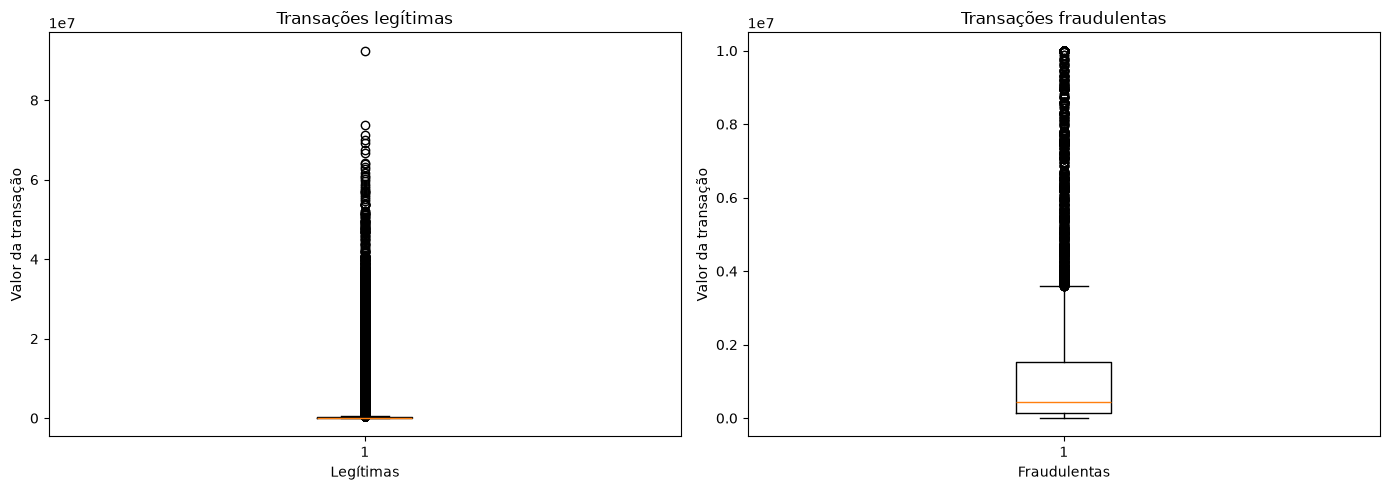

In [ ]:

# ============================================================
# ETAPA 21 — BOXPLOT DO VALOR DAS TRANSAÇÕES POR CLASSE
# ============================================================

# Criamos uma figura com dois gráficos lado a lado.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot das transações legítimas.
axes[0].boxplot(df.loc[df["isFraud"] == 0, "amount"])
axes[0].set_title("Transações legítimas")
axes[0].set_ylabel("Valor da transação")
axes[0].set_xlabel("Legítimas")

# Boxplot das transações fraudulentas.
axes[1].boxplot(df.loc[df["isFraud"] == 1, "amount"])
axes[1].set_title("Transações fraudulentas")
axes[1].set_ylabel("Valor da transação")
axes[1].set_xlabel("Fraudulentas")

# Ajustamos o espaçamento e exibimos os gráficos.
plt.tight_layout()
plt.show()


### ETAPA 22 — COMPARAÇÃO ESTATÍSTICA DOS VALORES POR CLASSE

In [ ]:

# ============================================================
# ETAPA 22 — COMPARAÇÃO ESTATÍSTICA DOS VALORES POR CLASSE
# ============================================================

# Calculamos estatísticas do valor das transações,
# separando os registros legítimos e fraudulentos.
comparacao_amount = df.groupby("isFraud")["amount"].agg(
    ["count", "mean", "median", "min", "max", "std"]
)

# Substituímos os códigos numéricos por nomes.
comparacao_amount.index = ["Legítimas", "Fraudulentas"]

# Arredondamos os resultados para facilitar a leitura.
display(comparacao_amount.round(2))


,count,mean,median,min,max,std
Legítimas,6354407,178197.04,74684.72,0.01,92445516.64,596236.98
Fraudulentas,8213,1467967.30,441423.44,0.00,10000000.00,2404252.95


### ETAPA 23 — OUTLIERS NAS VARIÁVEIS DE SALDO

In [ ]:

# ============================================================
# ETAPA 23 — OUTLIERS NAS VARIÁVEIS DE SALDO
# ============================================================

# Lista das variáveis financeiras que serão analisadas.
colunas_saldo = [
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

# Criamos uma lista para armazenar os resultados.
resultados_outliers = []

# Percorremos cada variável financeira.
for coluna in colunas_saldo:

    # Calculamos os quartis e a amplitude interquartil.
    q1 = df[coluna].quantile(0.25)
    q3 = df[coluna].quantile(0.75)
    iqr = q3 - q1

    # Calculamos os limites estatísticos.
    limite_inferior = q1 - (1.5 * iqr)
    limite_superior = q3 + (1.5 * iqr)

    # Identificamos os valores extremos.
    mascara_outliers = (
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior)
    )

    # Registramos a quantidade e o percentual encontrado.
    resultados_outliers.append({
        "Variável": coluna,
        "Limite inferior": round(limite_inferior, 2),
        "Limite superior": round(limite_superior, 2),
        "Quantidade de outliers": int(mascara_outliers.sum()),
        "Percentual (%)": round(mascara_outliers.mean() * 100, 2)
    })

# Transformamos os resultados em uma tabela.
tabela_outliers_saldo = pd.DataFrame(resultados_outliers)

# Exibimos a comparação.
display(tabela_outliers_saldo)


,Variável,Limite inferior,Limite superior,Quantidade de outliers,Percentual (%)
0,oldbalanceOrg,-160972.76,268287.94,1112507,17.49
1,newbalanceOrig,-216387.62,360646.02,1053391,16.56
2,oldbalanceDest,-1414555.06,2357591.77,786135,12.36
3,newbalanceDest,-1667863.88,2779773.12,738527,11.61


### ETAPA 24 — OUTLIERS DE SALDO POR CLASSE

In [ ]:


# ============================================================
# ETAPA 24 — OUTLIERS DE SALDO POR CLASSE
# ============================================================

# 1. Definimos as variáveis de saldo que serão analisadas.
# Essas colunas representam os saldos antes e depois das
# transações, tanto na origem quanto no destino.

colunas_saldo = [
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest'
]

# 2. Criamos uma lista vazia para armazenar os resultados
# da análise de cada variável.

resultados_por_classe = []

# 3. Percorremos cada variável de saldo para identificar
# possíveis valores extremos utilizando o método IQR.

for coluna in colunas_saldo:

    # Calculamos o primeiro quartil (Q1) e o terceiro quartil (Q3).
    q1 = df[coluna].quantile(0.25)
    q3 = df[coluna].quantile(0.75)

    # Calculamos a amplitude interquartil (IQR).
    iqr = q3 - q1

    # Definimos os limites inferior e superior para identificar
    # possíveis outliers.
    limite_inferior = q1 - (1.5 * iqr)
    limite_superior = q3 + (1.5 * iqr)

    # 4. Criamos uma máscara booleana:
    # True indica que o valor está fora dos limites definidos.
    # False indica que o valor está dentro dos limites.

    mascara_outliers = (
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior)
    )

    # 5. Calculamos o percentual de outliers separadamente
    # para transações legítimas (0) e fraudulentas (1).

    percentual_por_classe = (
        df.assign(outlier=mascara_outliers)
        .groupby("isFraud")["outlier"]
        .mean()
        .mul(100)
    )

    # 6. Armazenamos os percentuais calculados em uma lista,
    # facilitando a comparação entre as variáveis.

    resultados_por_classe.append({
        "Variável": coluna,
        "Legítimas (%)": round(percentual_por_classe.loc[0], 2),
        "Fraudulentas (%)": round(percentual_por_classe.loc[1], 2)
    })

# 7. Transformamos a lista de resultados em um DataFrame
# para organizar a comparação em formato de tabela.

comparacao_outliers_saldo = pd.DataFrame(resultados_por_classe)

# 8. Exibimos a tabela final com os percentuais de outliers
# encontrados em cada classe.

display(comparacao_outliers_saldo)



,Variável,Legítimas (%),Fraudulentas (%)
0,oldbalanceOrg,17.43,60.47
1,newbalanceOrig,16.57,1.89
2,oldbalanceDest,12.36,5.67
3,newbalanceDest,11.60,13.38


### ETAPA 25 — INVESTIGAÇÃO DE DATA LEAKAGE

In [ ]:
# ============================================================
# ETAPA 25 — INVESTIGAÇÃO DE DATA LEAKAGE
# ANÁLISE DA VARIÁVEL isFlaggedFraud
# ============================================================

# Criamos uma tabela cruzada entre a sinalização do sistema
# e a classificação real de fraude.

analise_flagged = pd.crosstab(
    df['isFlaggedFraud'],
    df['isFraud'],
    margins=True,
    rownames=['Sinalização do sistema'],
    colnames=['Classificação real']
)

# Exibimos os resultados.
display(analise_flagged)

Classificação real,0,1,All
Sinalização do sistema,,,
0,6354407,8197,6362604
1,0,16,16
All,6354407,8213,6362620


### ETAPA 26 — PERCENTUAL DE FRAUDES POR SINALIZAÇÃO

In [ ]:
# ============================================================
# ETAPA 26 — PERCENTUAL DE FRAUDES POR SINALIZAÇÃO
# ============================================================

# Calculei o percentual de transações legítimas e fraudulentas
# dentro de cada grupo de sinalização.

percentual_flagged = pd.crosstab(
    df['isFlaggedFraud'],
    df['isFraud'],
    normalize='index'
).mul(100).round(4)

# Exibimos os percentuais.
display(percentual_flagged)

isFraud,0,1
isFlaggedFraud,,
0,99.8712,0.1288
1,0.0000,100.0000


### ETAPA 27 — ANÁLISE DOS SALDOS ANTES E DEPOIS DA TRANSAÇÃO

In [ ]:
# ============================================================
# ETAPA 27 — ANÁLISE DOS SALDOS ANTES E DEPOIS DA TRANSAÇÃO
# ============================================================

# Comparei as médias e medianas dos saldos por classe de transação.

analise_saldos = (
    df.groupby('isFraud')[
        ['oldbalanceOrg', 'newbalanceOrig',
         'oldbalanceDest', 'newbalanceDest']
    ]
    .agg(['mean', 'median'])
    .round(2)
)

display(analise_saldos)

oldbalanceOrg            newbalanceOrig        oldbalanceDest  \
                 mean     median           mean median           mean   
isFraud                                                                 
0           832828.71   14069.00      855970.23    0.0     1101420.87   
1          1649667.61  438983.45      192392.63    0.0      544249.62   

                  newbalanceDest             
           median           mean     median  
isFraud                                      
0        133311.8     1224925.68  214881.70  
1             0.0     1279707.62    4676.42

### ETAPA 28 — CONSISTÊNCIA DOS SALDOS

In [ ]:
# ============================================================
# ETAPA 28 — CONSISTÊNCIA DOS SALDOS
# ============================================================

# Calculei a diferença entre o saldo inicial e o saldo final
# da conta de origem e da conta de destino.

df['variacao_saldo_origem'] = (
    df['oldbalanceOrg'] - df['newbalanceOrig']
)

df['variacao_saldo_destino'] = (
    df['newbalanceDest'] - df['oldbalanceDest']
)

# Comparei as médias dessas variações entre transações
# legítimas e fraudulentas.

analise_variacao = (
    df.groupby('isFraud')[
        ['variacao_saldo_origem', 'variacao_saldo_destino']
    ]
    .agg(['mean', 'median'])
    .round(2)
)

display(analise_variacao)

variacao_saldo_origem            variacao_saldo_destino       
                         mean     median                   mean median
isFraud                                                               
0                   -23141.52       0.00              123504.81    0.0
1                  1457274.97  436317.49              735458.00    0.0

### ETAPA 29 — COMPARAÇÃO ENTRE VALOR E VARIAÇÃO DO SALDO

In [ ]:

# ============================================================
# ETAPA 29 — COMPARAÇÃO ENTRE VALOR E VARIAÇÃO DO SALDO
# ============================================================

# Calculei a diferença entre o valor da transação
# e a variação do saldo da conta de origem.

df['diferenca_valor_origem'] = (
    df['amount'] - df['variacao_saldo_origem']
)

# Comparei os resultados entre transações legítimas
# e fraudulentas.

analise_diferenca = (
    df.groupby('isFraud')['diferenca_valor_origem']
    .agg(['mean', 'median', 'min', 'max'])
    .round(2)
)

display(analise_diferenca)


,mean,median,min,max
isFraud,,,,
0,201338.56,69049.31,-0.01,92445516.64
1,10692.33,0.00,-0.00,10000000.00


### ETAPA 30 — PROPORÇÃO DE DIFERENÇAS PRÓXIMAS DE ZERO

In [ ]:

# ============================================================
# ETAPA 30 — PROPORÇÃO DE DIFERENÇAS PRÓXIMAS DE ZERO
# ============================================================

# Verifiquei quantas transações apresentam diferença
# entre o valor movimentado e a variação do saldo
# da origem próxima de zero.

df['diferenca_proxima_zero'] = (
    np.isclose(
        df['diferenca_valor_origem'],
        0,
        atol=0.01
    )
)

# Calculei o percentual por classe.

percentual_diferenca = (
    df.groupby('isFraud')['diferenca_proxima_zero']
    .mean()
    .mul(100)
    .round(2)
)

# Exibi os resultados.

display(percentual_diferenca)


isFraud
0    20.27
1    99.45
Name: diferenca_proxima_zero, dtype: float64

### ETAPA 31 — DISTRIBUIÇÃO DE FRAUDES POR TIPO DE TRANSAÇÃO

In [ ]:

# ============================================================
# ETAPA 31 — DISTRIBUIÇÃO DE FRAUDES POR TIPO DE TRANSAÇÃO
# ============================================================

# Criei uma tabela para comparar os tipos de transação
# com a quantidade de operações legítimas e fraudulentas.

distribuicao_tipo = pd.crosstab(
    df['type'],
    df['isFraud'],
    margins=True,
    rownames=['Tipo de transação'],
    colnames=['Classificação']
)

# Exibi a quantidade de transações por tipo.
display(distribuicao_tipo)


Classificação,0,1,All
Tipo de transação,,,
CASH_IN,1399284,0,1399284
CASH_OUT,2233384,4116,2237500
DEBIT,41432,0,41432
PAYMENT,2151495,0,2151495
TRANSFER,528812,4097,532909
All,6354407,8213,6362620


### ETAPA 32 — TAXA DE FRAUDE POR TIPO DE TRANSAÇÃO

In [ ]:

# ============================================================
# ETAPA 32 — TAXA DE FRAUDE POR TIPO DE TRANSAÇÃO
# ============================================================

# Calculei a quantidade total de transações por tipo.
total_por_tipo = df.groupby('type').size()

# Calculei a quantidade de fraudes por tipo.
fraudes_por_tipo = df.groupby('type')['isFraud'].sum()

# Calculei a taxa percentual de fraude dentro de cada tipo.
taxa_fraude_tipo = (
    fraudes_por_tipo.div(total_por_tipo)
    .mul(100)
    .round(4)
)

# Organizei os resultados em uma tabela.
analise_taxa_tipo = pd.DataFrame({
    'Total de transações': total_por_tipo,
    'Total de fraudes': fraudes_por_tipo,
    'Taxa de fraude (%)': taxa_fraude_tipo
})

# Exibi a tabela ordenada pela taxa de fraude.
display(
    analise_taxa_tipo.sort_values(
        by='Taxa de fraude (%)',
        ascending=False
    )
)


,Total de transações,Total de fraudes,Taxa de fraude (%)
type,,,
TRANSFER,532909,4097,0.7688
CASH_OUT,2237500,4116,0.1840
CASH_IN,1399284,0,0.0000
DEBIT,41432,0,0.0000
PAYMENT,2151495,0,0.0000


### ETAPA 33 — GRÁFICO DA TAXA DE FRAUDE POR TIPO

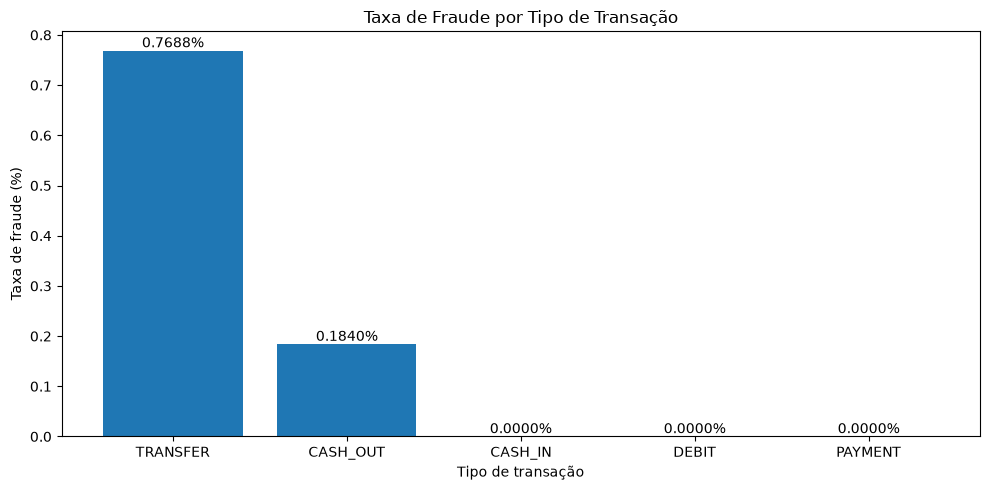

In [ ]:

# ============================================================
# ETAPA 33 — GRÁFICO DA TAXA DE FRAUDE POR TIPO
# ============================================================

# Ordenei os tipos de transação pela taxa de fraude.
dados_grafico = analise_taxa_tipo.sort_values(
    by='Taxa de fraude (%)',
    ascending=False
)

# Criei o gráfico de barras.
plt.figure(figsize=(10, 5))

plt.bar(
    dados_grafico.index,
    dados_grafico['Taxa de fraude (%)']
)

# Configurei o título e os nomes dos eixos.
plt.title('Taxa de Fraude por Tipo de Transação')
plt.xlabel('Tipo de transação')
plt.ylabel('Taxa de fraude (%)')

# Adicionei os valores sobre as barras.
for i, valor in enumerate(dados_grafico['Taxa de fraude (%)']):
    plt.text(i, valor, f'{valor:.4f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()


### ETAPA 34 — VALOR DAS TRANSAÇÕES POR TIPO E CLASSE

In [ ]:

# ============================================================
# ETAPA 34 — VALOR DAS TRANSAÇÕES POR TIPO E CLASSE
# ============================================================

# Comparei os valores das transações por tipo de operação
# e classificação, utilizando média, mediana e desvio padrão.

analise_valor_tipo = (
    df.groupby(['type', 'isFraud'])['amount']
    .agg(['count', 'mean', 'median', 'std'])
    .round(2)
)

# Exibi os resultados.
display(analise_valor_tipo)


count        mean     median         std
type     isFraud                                            
CASH_IN  0        1399284   168920.24  143427.71   126508.26
CASH_OUT 0        2233384   173917.16  146946.56   131222.24
         1           4116  1455102.59  435516.90  2393841.79
DEBIT    0          41432     5483.67    3048.99    13318.54
PAYMENT  0        2151495    13057.60    9482.19    12556.45
TRANSFER 0         528812   906229.01  486521.91  1874155.26
         1           4097  1480891.67  445705.76  2414890.38

### ETAPA 35 — DISTRIBUIÇÃO DOS VALORES POR TIPO E CLASSE

<Figure size 1200x600 with 0 Axes>

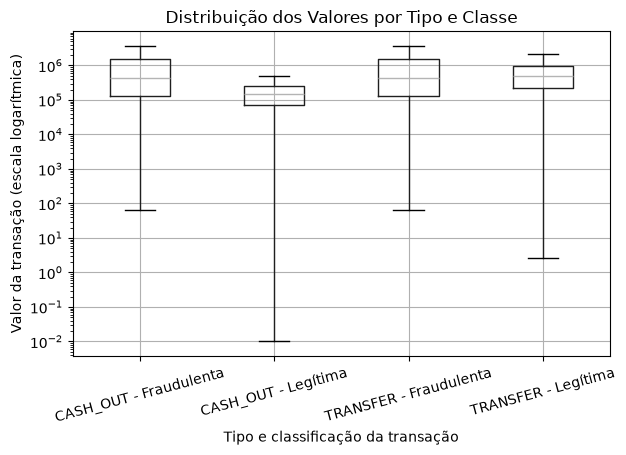

In [ ]:

# ============================================================
# ETAPA 35 — DISTRIBUIÇÃO DOS VALORES POR TIPO E CLASSE
# ============================================================

# Selecionei somente os tipos que apresentam fraudes.
dados_visualizacao = df[
    df['type'].isin(['CASH_OUT', 'TRANSFER'])
].copy()

# Criei uma coluna para identificar cada grupo.
dados_visualizacao['grupo'] = (
    dados_visualizacao['type'] + ' - ' +
    dados_visualizacao['isFraud'].map({
        0: 'Legítima',
        1: 'Fraudulenta'
    })
)

# Separei os valores positivos para utilizar escala logarítmica.
dados_visualizacao = dados_visualizacao[
    dados_visualizacao['amount'] > 0
]

# Criei o gráfico.
plt.figure(figsize=(12, 6))

dados_visualizacao.boxplot(
    column='amount',
    by='grupo',
    showfliers=False
)

plt.yscale('log')
plt.title('Distribuição dos Valores por Tipo e Classe')
plt.suptitle('')
plt.xlabel('Tipo e classificação da transação')
plt.ylabel('Valor da transação (escala logarítmica)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


### ETAPA 36 — QUARTIS DO VALOR POR TIPO E CLASSE

In [ ]:

# ============================================================
# ETAPA 36 — QUARTIS DO VALOR POR TIPO E CLASSE
# ============================================================

# Calculei os quartis dos valores das transações
# separando por tipo de operação e classificação.

quartis_valor_tipo = (
    df.groupby(['type', 'isFraud'])['amount']
    .quantile([0.25, 0.50, 0.75])
    .unstack()
)

# Renomeei as colunas para facilitar a interpretação.
quartis_valor_tipo.columns = [
    'Q1 (25%)',
    'Mediana (50%)',
    'Q3 (75%)'
]

# Arredondei os valores.
quartis_valor_tipo = quartis_valor_tipo.round(2)

# Exibi os resultados.
display(quartis_valor_tipo)


Q1 (25%)  Mediana (50%)    Q3 (75%)
type     isFraud                                      
CASH_IN  0         70510.18      143427.71   239899.09
CASH_OUT 0         72627.69      146946.56   246181.18
         1        125464.45      435516.90  1500761.03
DEBIT    0          1500.18        3048.99     5479.18
PAYMENT  0          4383.82        9482.19    17561.22
TRANSFER 0        216570.76      486521.91   972733.64
         1        128417.96      445705.76  1534985.07

### ETAPA 37 — INVESTIGAÇÃO DE IDENTIFICADORES E TEMPO

In [ ]:

# ============================================================
# ETAPA 37 — INVESTIGAÇÃO DE IDENTIFICADORES E TEMPO
# ============================================================

# Analisei a quantidade de identificadores únicos
# nas contas de origem e destino.

colunas_id = ['nameOrig', 'nameDest']

resumo_identificadores = pd.DataFrame({
    'Registros': len(df),
    'Valores únicos': [
        df[coluna].nunique()
        for coluna in colunas_id
    ],
    'Percentual de valores únicos (%)': [
        round((df[coluna].nunique() / len(df)) * 100, 2)
        for coluna in colunas_id
    ]
}, index=colunas_id)

display(resumo_identificadores)

# Analisei o comportamento temporal por classe.
analise_temporal = (
    df.groupby('isFraud')['step']
    .agg(['min', 'median', 'max', 'nunique'])
    .round(2)
)

display(analise_temporal)


### ETAPA 38 — TAXA DE FRAUDE AO LONGO DO TEMPO

In [ ]:

# ============================================================
# ETAPA 38 — TAXA DE FRAUDE AO LONGO DO TEMPO
# ============================================================

# Agrupei os registros em intervalos de 24 unidades de step.
# Cada faixa recebe um identificador numérico.

df['faixa_step'] = ((df['step'] - 1) // 24) + 1

# Calculei o volume de transações e a quantidade de fraudes
# em cada intervalo temporal.

analise_temporal_fraudes = (
    df.groupby('faixa_step')
    .agg(
        total_transacoes=('isFraud', 'size'),
        total_fraudes=('isFraud', 'sum')
    )
)

# Calculei o percentual de fraudes dentro de cada faixa.

analise_temporal_fraudes['taxa_fraude_pct'] = (
    analise_temporal_fraudes['total_fraudes']
    .div(analise_temporal_fraudes['total_transacoes'])
    .mul(100)
    .round(4)
)

# Exibi os resultados.

display(analise_temporal_fraudes)


,total_transacoes,total_fraudes,taxa_fraude_pct
faixa_step,,,
1,574255,271,0.0472
2,455238,309,0.0679
3,1070,310,28.9720
4,28240,262,0.9278
5,9789,252,2.5743
6,441005,228,0.0517
7,420583,272,0.0647
8,449637,278,0.0618
9,417919,255,0.0610


### ETAPA 39 — DETALHAMENTO DOS INTERVALOS TEMPORAIS

In [ ]:

# ============================================================
# ETAPA 39 — DETALHAMENTO DOS INTERVALOS TEMPORAIS
# ============================================================

# Detalhei os valores de step e o volume de transações
# em cada faixa temporal.

analise_temporal_detalhada = (
    df.groupby('faixa_step')
    .agg(
        step_inicial=('step', 'min'),
        step_final=('step', 'max'),
        steps_distintos=('step', 'nunique'),
        total_transacoes=('isFraud', 'size'),
        total_fraudes=('isFraud', 'sum')
    )
)

# Calculei novamente a taxa de fraude por faixa.

analise_temporal_detalhada['taxa_fraude_pct'] = (
    analise_temporal_detalhada['total_fraudes']
    .div(analise_temporal_detalhada['total_transacoes'])
    .mul(100)
    .round(4)
)

# Exibi os resultados.
display(analise_temporal_detalhada)


,step_inicial,step_final,steps_distintos,total_transacoes,total_fraudes,taxa_fraude_pct
faixa_step,,,,,,
1,1,24,24,574255,271,0.0472
2,25,48,24,455238,309,0.0679
3,49,72,24,1070,310,28.9720
4,73,96,24,28240,262,0.9278
5,97,120,24,9789,252,2.5743
6,121,144,24,441005,228,0.0517
7,145,168,24,420583,272,0.0647
8,169,192,24,449637,278,0.0618
9,193,216,24,417919,255,0.0610


### ETAPA 40 — DISTRIBUIÇÃO DE FRAUDES NOS STEPS FINAIS

In [ ]:

# ============================================================
# ETAPA 40 — DISTRIBUIÇÃO DE FRAUDES NOS STEPS FINAIS
# ============================================================

# Selecionei as transações a partir do step 697.
# Assim conseguimos investigar a parte final da simulação.

dados_finais = df[df['step'] >= 697]

# Cruzei cada step com a classificação das transações.

distribuicao_steps_finais = pd.crosstab(
    dados_finais['step'],
    dados_finais['isFraud']
)

# Garanti a presença das duas classes na tabela.
distribuicao_steps_finais = (
    distribuicao_steps_finais
    .reindex(columns=[0, 1], fill_value=0)
)

# Renomeei as colunas para facilitar a leitura.

distribuicao_steps_finais.columns = [
    'Transações legítimas',
    'Transações fraudulentas'
]

# Calculei o total de transações por step.

distribuicao_steps_finais['Total'] = (
    distribuicao_steps_finais.sum(axis=1)
)

# Calculei a taxa de fraude em cada step.

distribuicao_steps_finais['Taxa de fraude (%)'] = (
    distribuicao_steps_finais['Transações fraudulentas']
    .div(distribuicao_steps_finais['Total'])
    .mul(100)
    .round(2)
)

display(distribuicao_steps_finais)


,Transações legítimas,Transações fraudulentas,Total,Taxa de fraude (%)
step,,,,
697,0,12,12,100.00
698,49,16,65,24.62
699,39,16,55,29.09
700,0,6,6,100.00
701,0,18,18,100.00
702,0,14,14,100.00
703,0,8,8,100.00
704,0,16,16,100.00
705,2352,10,2362,0.42


### ETAPA 41 — MATRIZ PRELIMINAR DE DECISÃO DAS VARIÁVEIS

In [ ]:

# ============================================================
# ETAPA 41 — MATRIZ PRELIMINAR DE DECISÃO DAS VARIÁVEIS
# ============================================================

# Organizei as variáveis analisadas e as decisões preliminares
# para orientar a preparação dos dados para Machine Learning.

decisoes_variaveis = [
    {
        'Variável': 'amount',
        'Decisão': 'Manter',
        'Justificativa': 'Apresenta diferenças entre as classes.'
    },
    {
        'Variável': 'type',
        'Decisão': 'Manter',
        'Justificativa': 'As fraudes estão concentradas em TRANSFER e CASH_OUT.'
    },
    {
        'Variável': 'oldbalanceOrg',
        'Decisão': 'Manter',
        'Justificativa': 'Representa o saldo antes da transação.'
    },
    {
        'Variável': 'oldbalanceDest',
        'Decisão': 'Manter',
        'Justificativa': 'Representa o saldo antes da transação.'
    },
    {
        'Variável': 'newbalanceOrig',
        'Decisão': 'Investigar',
        'Justificativa': 'Representa informação posterior à transação.'
    },
    {
        'Variável': 'newbalanceDest',
        'Decisão': 'Investigar',
        'Justificativa': 'Representa informação posterior à transação.'
    },
    {
        'Variável': 'isFlaggedFraud',
        'Decisão': 'Excluir',
        'Justificativa': 'Representa uma regra preexistente de sinalização.'
    },
    {
        'Variável': 'nameOrig',
        'Decisão': 'Excluir bruto',
        'Justificativa': 'Apresenta cardinalidade muito alta.'
    },
    {
        'Variável': 'nameDest',
        'Decisão': 'Excluir bruto',
        'Justificativa': 'Apresenta cardinalidade elevada.'
    },
    {
        'Variável': 'step',
        'Decisão': 'Testar',
        'Justificativa': 'Apresenta concentração temporal de fraudes.'
    },
    {
        'Variável': 'isFraud',
        'Decisão': 'Target',
        'Justificativa': 'Representa a variável que queremos prever.'
    }
]

# Transformei os registros em uma tabela.
matriz_decisao = pd.DataFrame(decisoes_variaveis)

# Exibi a matriz para consulta.
display(matriz_decisao)


,Variável,Decisão,Justificativa
0,amount,Manter,Apresenta diferenças entre as classes.
1,type,Manter,As fraudes estão concentradas em TRANSFER e CA...
2,oldbalanceOrg,Manter,Representa o saldo antes da transação.
3,oldbalanceDest,Manter,Representa o saldo antes da transação.
4,newbalanceOrig,Investigar,Representa informação posterior à transação.
5,newbalanceDest,Investigar,Representa informação posterior à transação.
6,isFlaggedFraud,Excluir,Representa uma regra preexistente de sinalização.
7,nameOrig,Excluir bruto,Apresenta cardinalidade muito alta.
8,nameDest,Excluir bruto,Apresenta cardinalidade elevada.
9,step,Testar,Apresenta concentração temporal de fraudes.


### ETAPA 42 — DIAGNÓSTICO DE MISSING VALUES

In [ ]:

# ============================================================
# ETAPA 42 — DIAGNÓSTICO DE MISSING VALUES
# ============================================================

# Verifiquei a quantidade de valores ausentes em cada coluna.

diagnostico_missing = pd.DataFrame({
    'Valores ausentes': df.isnull().sum(),
    'Percentual ausente (%)': (
        df.isnull().mean() * 100
    ).round(4),
    'Tipo de dado': df.dtypes.astype(str)
})

# Ordenei pelas colunas com maior quantidade de ausências.

diagnostico_missing = diagnostico_missing.sort_values(
    by='Valores ausentes',
    ascending=False
)

# Exibi o diagnóstico.

display(diagnostico_missing)


,Valores ausentes,Percentual ausente (%),Tipo de dado
step,0,0.0,int64
type,0,0.0,str
amount,0,0.0,float64
nameOrig,0,0.0,str
oldbalanceOrg,0,0.0,float64
newbalanceOrig,0,0.0,float64
nameDest,0,0.0,str
oldbalanceDest,0,0.0,float64
newbalanceDest,0,0.0,float64
isFraud,0,0.0,int64


### ETAPA 43 — DIAGNÓSTICO DE REGISTROS DUPLICADOS

In [ ]:

# ============================================================
# ETAPA 43 — DIAGNÓSTICO DE REGISTROS DUPLICADOS
# ============================================================

# Verifiquei quantas linhas são completamente duplicadas
# considerando todas as colunas disponíveis no DataFrame.

total_duplicados = df.duplicated().sum()

# Calculei o percentual de duplicações.

percentual_duplicados = (
    total_duplicados / len(df) * 100
)

# Organizei os resultados em uma tabela.

diagnostico_duplicados = pd.DataFrame({
    'Indicador': [
        'Total de registros',
        'Registros duplicados',
        'Registros sem duplicação',
        'Percentual de duplicação (%)'
    ],
    'Resultado': [
        len(df),
        total_duplicados,
        len(df) - total_duplicados,
        round(percentual_duplicados, 4)
    ]
})

# Exibi o diagnóstico.

display(diagnostico_duplicados)


,Indicador,Resultado
0,Total de registros,6362620.0
1,Registros duplicados,0.0
2,Registros sem duplicação,6362620.0
3,Percentual de duplicação (%),0.0


### ETAPA 44 — CRIAÇÃO DA BASE INICIAL PARA MACHINE LEARNING

In [ ]:

# ============================================================
# ETAPA 44 — CRIAÇÃO DA BASE INICIAL PARA MACHINE LEARNING
# ============================================================

# Separei as variáveis candidatas para os primeiros experimentos
# de treinamento dos modelos KNN e LightGBM.

colunas_ml = [
    'step',
    'type',
    'amount',
    'oldbalanceOrg',
    'oldbalanceDest',
    'isFraud'
]

# Criei uma cópia independente da base original.
df_ml_base = df[colunas_ml].copy()

# Verifiquei o tamanho da nova base.
print("Dimensões da base para ML:", df_ml_base.shape)

# Conferi as primeiras linhas.
display(df_ml_base.head())

# Conferi os tipos de dados.
display(df_ml_base.dtypes)


Dimensões da base para ML: (6362620, 6)


,step,type,amount,oldbalanceOrg,oldbalanceDest,isFraud
0,1,PAYMENT,9839.64,170136.0,0.0,0
1,1,PAYMENT,1864.28,21249.0,0.0,0
2,1,TRANSFER,181.00,181.0,0.0,1
3,1,CASH_OUT,181.00,181.0,21182.0,1
4,1,PAYMENT,11668.14,41554.0,0.0,0


step                int64
type                  str
amount            float64
oldbalanceOrg     float64
oldbalanceDest    float64
isFraud             int64
dtype: object

### ETAPA 45 — DISTRIBUIÇÃO DAS CLASSES NA BASE DE ML

In [ ]:

# ============================================================
# ETAPA 45 — DISTRIBUIÇÃO DAS CLASSES NA BASE DE ML
# ============================================================

# Calculei a quantidade de transações legítimas e fraudulentas.
quantidade_classes = df_ml_base['isFraud'].value_counts()

# Calculei o percentual de cada classe.
percentual_classes = (
    df_ml_base['isFraud']
    .value_counts(normalize=True)
    .mul(100)
)

# Organizei os resultados em uma tabela.
distribuicao_classes = pd.DataFrame({
    'Quantidade': quantidade_classes,
    'Percentual (%)': percentual_classes.round(4)
})

# Renomeei os índices para facilitar a leitura.
distribuicao_classes.index = [
    'Legítimas' if classe == 0 else 'Fraudulentas'
    for classe in distribuicao_classes.index
]

# Exibi a distribuição.
display(distribuicao_classes)


,Quantidade,Percentual (%)
Legítimas,6354407,99.8709
Fraudulentas,8213,0.1291


### ETAPA 46 — PROPORÇÃO DE DESBALANCEAMENTO

In [ ]:

# ============================================================
# ETAPA 46 — PROPORÇÃO DE DESBALANCEAMENTO
# ============================================================

# Calculei a quantidade de transações de cada classe.

quantidade_legitimas = int(
    (df_ml_base['isFraud'] == 0).sum()
)

quantidade_fraudes = int(
    (df_ml_base['isFraud'] == 1).sum()
)

# Calculei a proporção entre a classe majoritária
# e a classe minoritária.

razao_desbalanceamento = (
    quantidade_legitimas / quantidade_fraudes
)

# Simulei um classificador que prevê todas as transações
# como legítimas.

acuracia_baseline = (
    quantidade_legitimas / len(df_ml_base)
) * 100

# Nesse cenário, nenhuma fraude seria identificada.
recall_baseline = 0.0

# Organizei os resultados em uma tabela.

analise_desbalanceamento = pd.DataFrame({
    'Indicador': [
        'Transações legítimas por fraude',
        'Acurácia do classificador ingênuo (%)',
        'Recall do classificador ingênuo (%)'
    ],
    'Resultado': [
        round(razao_desbalanceamento, 2),
        round(acuracia_baseline, 4),
        recall_baseline
    ]
})

display(analise_desbalanceamento)


,Indicador,Resultado
0,Transações legítimas por fraude,773.7000
1,Acurácia do classificador ingênuo (%),99.8709
2,Recall do classificador ingênuo (%),0.0000


# ETAPA 47 — ENCERRAMENTO DA INVESTIGAÇÃO DE DATA LEAKAGE

**Projeto:** Grupo 5 — Cidade Inteligente | Auditoria e Prevenção de Fraudes  
**Responsável:** João Batista — FinOps/ML  
**Data:** 14/11/2026

## 1. Objetivo

Concluir a investigação de Data Leakage e definir as variáveis que poderão ser utilizadas nos experimentos de Machine Learning, considerando o objetivo de identificar transações suspeitas antes de sua conclusão.

## 2. Principais descobertas

- `isFlaggedFraud`: somente 16 transações foram sinalizadas, diante de 8.213 fraudes identificadas.
- `newbalanceOrig` e `newbalanceDest`: representam saldos posteriores à transação.
- Variáveis de saldo: a documentação do PaySim recomenda não utilizar as quatro colunas de saldo na detecção, considerando que transações identificadas como fraude são canceladas.
- `nameOrig` e `nameDest`: apresentam cardinalidade elevada.
- `step`: apresenta concentração de fraudes no final da simulação, especialmente entre os steps 721 e 743.

## 3. Decisões

**Variáveis mantidas no modelo principal:**
- `amount`
- `type`

**Variável para experimento comparativo:**
- `step`

**Variáveis excluídas do modelo principal:**
- `oldbalanceOrg`
- `newbalanceOrig`
- `oldbalanceDest`
- `newbalanceDest`
- `isFlaggedFraud`
- `nameOrig`
- `nameDest`

**Variável-alvo:**
- `isFraud`

As variáveis auxiliares criadas a partir dos saldos posteriores também ficarão fora do modelo principal.

## 4. Estratégia de validação

Será realizada uma comparação entre experimentos com e sem a variável `step`, utilizando uma estratégia de validação temporal para avaliar a capacidade de generalização dos modelos.

## 5. Conclusão

A investigação identificou variáveis com risco de vazamento temporal, regras preexistentes de classificação, identificadores com alta cardinalidade e padrões temporais específicos do simulador.

As decisões foram tomadas considerando o objetivo de prevenção de fraudes e as particularidades do dataset sintético PaySim.

**Status:** investigação de Data Leakage concluída para a definição inicial dos experimentos de ML.

## Apêndice — Registro de atividades

# REGISTRO DE ATIVIDADES — FINOPS/ML
## Projeto Integrador — Grupo 5 | Cidade Inteligente: Auditoria e Prevenção de Fraudes

**Data:** 14/11/2026  
**Responsável:** João Batista — FinOps/ML  
**Frente colaborativa:** Engenharia de Dados e FinOps/ML  
**Status:** EDA concluída — preparação para Machine Learning em andamento

---

## 1. Atividades realizadas

Foi desenvolvida a análise exploratória de dados (EDA) do dataset PaySim, com o objetivo de compreender o comportamento das transações legítimas e fraudulentas e identificar características relevantes para a construção dos modelos de Machine Learning.

As análises realizadas incluíram:

- Distribuição dos valores das transações (`amount`).
- Comparação estatística entre transações legítimas e fraudulentas.
- Identificação de saldos zerados nas contas de origem e destino.
- Identificação de outliers pelo método IQR.
- Comparação de outliers entre as classes legítimas e fraudulentas.
- Análise da distribuição das variáveis de saldo antes e depois das transações.

### Principais observações

- As transações fraudulentas apresentam valores médios e medianos superiores aos das transações legítimas.
- A presença de outliers é mais expressiva em determinadas variáveis de saldo e na classe fraudulenta.
- Valores extremos não devem ser considerados automaticamente como fraudes.
- Saldos zerados não devem ser tratados automaticamente como valores ausentes.

**Decisão técnica:** não realizar exclusão indiscriminada de outliers ou saldos zerados. O tratamento deverá considerar o comportamento das variáveis e a preservação dos padrões relevantes para a identificação de fraudes.

---

## 2. Próxima etapa — Investigação de Data Leakage

Antes de iniciar a preparação definitiva dos dados e o treinamento dos modelos, será realizada uma investigação de possíveis vazamentos de informação (*Data Leakage*).

O objetivo é identificar variáveis que possam fornecer ao modelo informações que não estariam disponíveis no momento em que uma transação precisaria ser avaliada.

### Variáveis prioritárias para investigação

| Variável | Motivo da investigação |
|---|---|
| `isFlaggedFraud` | Pode representar uma sinalização preexistente de fraude, permitindo que o modelo reproduza uma regra anterior. |
| `newbalanceOrig` | Representa o saldo da origem após a transação. |
| `newbalanceDest` | Representa o saldo do destino após a transação. |

### Análises previstas

1. Investigar a relação entre `isFlaggedFraud` e `isFraud`.
2. Identificar quantas fraudes foram sinalizadas pela regra preexistente.
3. Verificar quantas fraudes não foram sinalizadas.
4. Avaliar a disponibilidade temporal das variáveis de saldo após a transação.
5. Documentar quais variáveis poderão ser utilizadas nos modelos e justificar as exclusões, quando necessárias.

**Importante:** nenhuma variável será excluída sem análise e justificativa técnica.

---

## 3. Planejamento das próximas entregas de FinOps/ML

Após a investigação de Data Leakage, serão executadas as seguintes atividades:

| Ordem | Atividade | Entrega |
|---|---|---|
| 1 | Investigação de Data Leakage | Relatório de variáveis elegíveis para modelagem |
| 2 | Tratamento de Missing Values | Estratégia de imputação documentada |
| 3 | Tratamento de outliers | Estratégia de identificação e tratamento |
| 4 | Binning | Criação de faixas para variáveis relevantes |
| 5 | Feature Engineering | Novas